<a href="https://colab.research.google.com/github/jelvalojel-glitch/ML_task_07/blob/main/task07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (1).csv
СРАВНЕНИЕ МОДЕЛЕЙ:


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Дерево решений,0.9129,0.1579,0.18,0.1682,0.5653
1,Лес по умолчанию,0.9491,0.3333,0.04,0.0714,0.7796
2,Настроенный лес,0.9491,0.3333,0.04,0.0714,0.7796


Лучшие параметры: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
F1 на кросс-валидации: 0.0191
Количество деревьев: 100

ВАЖНОСТЬ ПРИЗНАКОВ:


,Permutation importance
age,0.0637
work_type,0.0495
smoking_status,0.0417
hypertension,0.0345
ever_married,0.0220
Residence_type,0.0206
gender,0.0202
avg_glucose_level,0.0195
heart_disease,-0.0008
bmi,-0.0018


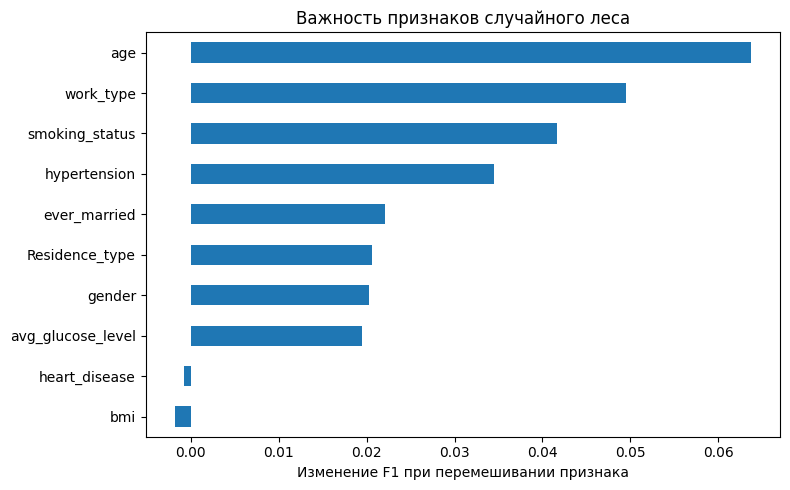


РЕЗУЛЬТАТЫ УДАЛЕНИЯ ПРИЗНАКОВ:


,Эксперимент,Количество признаков,Accuracy,Recall,F1,ROC-AUC
0,Все признаки,10,0.9491,0.04,0.0714,0.7796
1,Удалены 1 наименее важных,9,0.9452,0.02,0.0345,0.7606
2,Удалены 2 наименее важных,8,0.9452,0.02,0.0345,0.7425


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Загрузка данных
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# 2. Подготовка данных
df = df.dropna(subset=["stroke"])
X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

def get_preprocessor(active_num_cols, active_cat_cols):
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), active_num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), active_cat_cols)
    ])

def make_model(estimator, active_num_cols=num_cols, active_cat_cols=cat_cols):
    return Pipeline([
        ("prep", get_preprocessor(active_num_cols, active_cat_cols)),
        ("model", estimator)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Одиночное дерево
tree = make_model(DecisionTreeClassifier(random_state=42))
tree.fit(X_train, y_train)

# 4. Случайный лес по умолчанию
default_forest = make_model(
    RandomForestClassifier(random_state=42, n_jobs=-1)
)
default_forest.fit(X_train, y_train)

# 5. Подбор гиперпараметров
grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4]
}

search = GridSearchCV(
    make_model(RandomForestClassifier(random_state=42, n_jobs=-1)),
    grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)
search.fit(X_train, y_train)
best_forest = search.best_estimator_

# 6. Сравнение моделей
def evaluate(model, name, X_eval=X_test):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

results = pd.DataFrame([
    evaluate(tree, "Дерево решений"),
    evaluate(default_forest, "Лес по умолчанию"),
    evaluate(best_forest, "Настроенный лес")
])

print("СРАВНЕНИЕ МОДЕЛЕЙ:")
display(results.round(4))
print("Лучшие параметры:", search.best_params_)
print("F1 на кросс-валидации:", round(search.best_score_, 4))
print("Количество деревьев:", best_forest.named_steps["model"].n_estimators)

# 7. Важность исходных признаков
perm = permutation_importance(
    best_forest, X_test, y_test,
    scoring="f1", n_repeats=5,
    random_state=42, n_jobs=-1
)

importance = pd.Series(
    perm.importances_mean, index=X_test.columns
).sort_values(ascending=False)

print("\nВАЖНОСТЬ ПРИЗНАКОВ:")
display(importance.rename("Permutation importance").to_frame().round(4))

importance.sort_values().plot(
    kind="barh", figsize=(8, 5)
)
plt.title("Важность признаков случайного леса")
plt.xlabel("Изменение F1 при перемешивании признака")
plt.tight_layout()
plt.show()

# 8. Эксперимент: удаление наименее важных признаков
ranked = importance.index.tolist()
experiments = [("Все признаки", ranked)]

for k in [1, 2]:
    if len(ranked) > k:
        experiments.append((
            f"Удалены {k} наименее важных",
            ranked[:-k]
        ))

drop_results = []

for name, cols in experiments:
    # Выделяем только те численные и категориальные признаки, которые остались
    current_num_cols = [c for c in num_cols if c in cols]
    current_cat_cols = [c for c in cat_cols if c in cols]

    model = make_model(
        RandomForestClassifier(
            **{
                key.replace("model__", ""): value
                for key, value in search.best_params_.items()
            },
            random_state=42,
            n_jobs=-1
        ),
        active_num_cols=current_num_cols,
        active_cat_cols=current_cat_cols
    )
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    prob = model.predict_proba(X_test[cols])[:, 1]

    drop_results.append({
        "Эксперимент": name,
        "Количество признаков": len(cols),
        "Accuracy": accuracy_score(y_test, pred),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

print("\nРЕЗУЛЬТАТЫ УДАЛЕНИЯ ПРИЗНАКОВ:")
display(pd.DataFrame(drop_results).round(4))